In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.utils import resample

# Bagging

Given a Dataset $D =  \{x_i\}_i $ of $N$ datapoints.

Bootstrap Aggregation is a statistical procedure whether we artificially create multiple datasets from the  Dataset by sampling with replacement giving us $\{D_k\}_{k=1}^B$ datasets, and allows us to have -using the same training procedure- $B$ base learners $\theta_k$ .

Suppose $\theta_k \sim \mu , \sigma^2 $ and that $corr(\theta_i, \theta_j) = \rho_{i,j} = \rho $ and let $\theta_{bag} = \frac{1}{B} \sum_{k=1}^{B} \theta_k$.

$$
\begin{align}
\mathbb{E}(\theta_{bag}) &= \mu     \\ 
\text{Var}(\theta_{bag}) &= \frac{1-\rho}{B}\sigma^2 + \rho \sigma^2 
\end{align}
$$

Since the B learners train on correlated datasets, they make similar predictions. 

**The Idiosyncratic Variance** : $(1-\rho)\sigma^2$ quantifies  the portion of the models' errors (variance) that is completely independent from one another and can therefore be averaged away, ie the idiosyncratic variance to each model.

**The Shared Variance** :  $\rho \sigma^2$ remains constant regardless of how many models you add. Because it is common across all models, averaging does absolutely nothing to reduce it. If every model makes the exact same mistake, the average of those models will make that exact same mistake.

**(2)** :  **Bagging reduces variance strictly by attacking the $(1-\rho)$ term**, but it is mathematically incapable of reducing the $\rho\sigma^2$ term. This explicit mathematical bottleneck is exactly what motivates **Random Forests**: by forcing trees to split on random subsets of features, Random Forests artificially decrease $\rho$, thereby lowering the structural variance floor that standard bagging cannot touch. 

**(1)** : **The expected value of the ensemble prediction is strictly identical to the expected value of a single base learner.** Therefore, bagging does absolutely nothing to reduce bias. It does not shift the center of the prediction distribution; it only narrows the spread around that center.
This mathematical reality dictates our choice of base learner. If bagging drastically reduces variance but leaves bias completely unchanged, the optimal strategy is to pair it with a base learner that possesses exceptionally low bias, even if that comes at the cost of wildly high variance. This is why **bagging is almost exclusively paired with deep, unpruned decision trees. A single unpruned tree will heavily overfit the training data (exhibiting massive variance) but will flawlessly map complex, non-linear boundaries (exhibiting near-zero bias).**

Bagging acts as the statistical stabilizer, averaging out the volatile overfitting while perfectly preserving the intricate, low-bias decision boundaries.

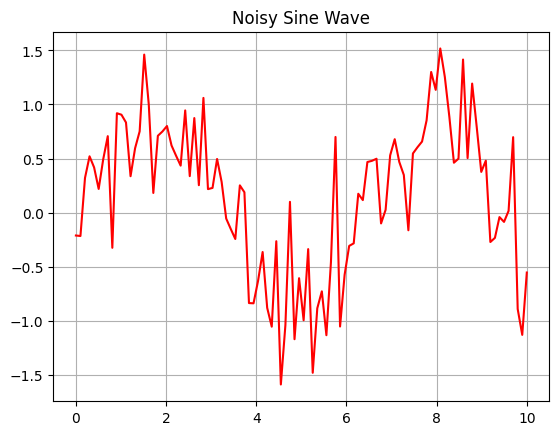

In [13]:
np.random.seed(571)

# Noisy sine wave dataset
X_train = np.linspace(0,10,100).reshape(-1,1)
y_train = np.sin(X_train).ravel() + np.random.normal(0, 0.4, X_train.shape[0])

plt.plot(X_train, y_train, color='red')
plt.grid()
plt.title(label="Noisy Sine Wave")

X_test = np.linspace(0, 10, 500).reshape(-1, 1)
y_true = np.sin(X_test).ravel()

In [ ]:
B = 50  # Number of bootstrapped trees
predictions = np.zeros((B, len(X_test)))


for i in range(B):
    X_boot, y_boot = resample(X_train, y_train)
    tree = DecisionTreeRegressor(max_depth=6)
    tree.fit(X_boot, y_boot)
    predictions[i, :] = tree.predict(X_test)

bagged_prediction = np.mean(predictions, axis=0)

test_idx = 250
single_tree_variance = np.var(predictions[:, test_idx])
bagged_variance = single_tree_variance / B  # Simplified theoretical drop (assuming independent trees)
actual_bagged_variance = np.var([np.mean(resample(predictions[:, test_idx])) for _ in range(100)]) 
# (In practice, trees are correlated (rho > 0), so the variance doesn't drop to 0)

print(f"Mean of single tree predictions at X={X_test[test_idx][0]:.2f}: {np.mean(predictions[:, test_idx]):.4f}")
print(f"Bagged model prediction at X={X_test[test_idx][0]:.2f}:       {bagged_prediction[test_idx]:.4f}")
print("-" * 40)
print(f"Variance of a single tree's prediction: {single_tree_variance:.4f}")
print(f"Variance of the Bagged ensemble:        {actual_bagged_variance:.4f}")

Mean of single tree predictions at X=5.01: -0.7828
Bagged model prediction at X=5.01:       -0.7828
----------------------------------------
Variance of a single tree's prediction: 0.0478
Variance of the Bagged ensemble:        0.0007


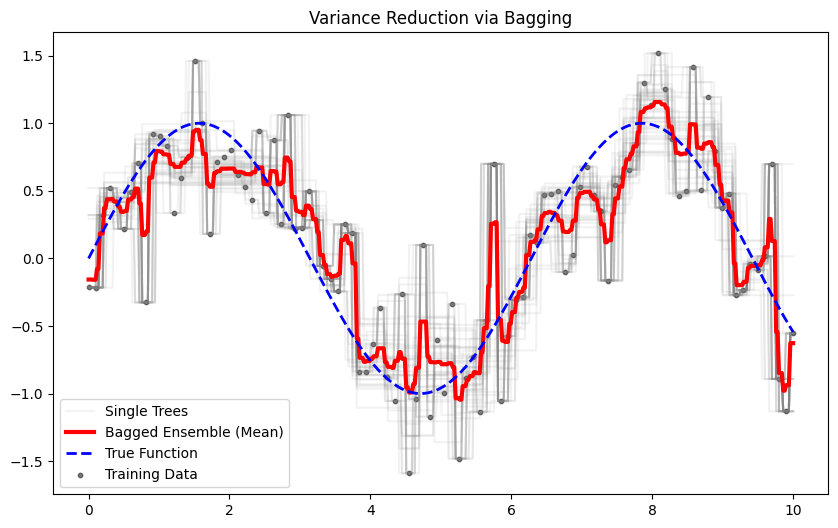

In [17]:
plt.figure(figsize=(10, 6))

# Plot all individual trees 
for i in range(B):
    plt.plot(X_test, predictions[i], color='gray', alpha=0.1, 
             label='Single Trees' if i == 0 else "")

# Plot the Bagged Ensemble 
plt.plot(X_test, bagged_prediction, color='red', linewidth=3, label='Bagged Ensemble (Mean)')
plt.plot(X_test, y_true, color='blue', linestyle='--', linewidth=2, label='True Function')
plt.scatter(X_train, y_train, color='black', s=10, alpha=0.5, label='Training Data')

plt.title("Variance Reduction via Bagging")
plt.legend()
plt.show()